In [ ]:
import os
import time
import random
import copy
import math
from collections import deque, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as transforms

In [ ]:

SEED = 42


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Seed:", SEED)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Seed: 42
Device: cuda
GPU: Tesla T4


In [ ]:


NUM_CLIENTS = 50

CLIENTS_PER_ROUND = 10

NUM_ROUNDS = 50

NUM_CLASSES = 10

BATCH_SIZE = 64

LEARNING_RATE = 0.001

LOCAL_EPOCH_MIN = 1

LOCAL_EPOCH_MAX = 5

NON_IID_ALPHA = 0.3

RL_GAMMA = 0.95

RL_LR = 1e-3

REPLAY_CAPACITY = 10000

RL_BATCH_SIZE = 64

TARGET_UPDATE_FREQ = 5

EPSILON_START = 1.0

EPSILON_END = 0.05

EPSILON_DECAY = 0.95

CPU_MIN = 1.0
CPU_MAX = 8.0

BATTERY_MIN = 20.0
BATTERY_MAX = 100.0

BANDWIDTH_MIN = 5.0
BANDWIDTH_MAX = 100.0

LATENCY_MIN = 20.0
LATENCY_MAX = 200.0

W_GLOBAL_ACCURACY = 0.45
W_DATA_UTILITY = 0.15
W_TIME = 0.15
W_COMMUNICATION = 0.10
W_ENERGY = 0.10
W_FAIRNESS = 0.05

W_LOCAL_ACCURACY = 0.50
W_LOCAL_TIME = 0.20
W_LOCAL_ENERGY = 0.15
W_LOCAL_COMMUNICATION = 0.15

MODEL_SIZE_MB = 2.0


print("Configuration loaded.")

Configuration loaded.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:


DATA_PATH = "/content/drive/MyDrive/RL-project/CIFAR10"


os.makedirs(DATA_PATH, exist_ok=True)


transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])


train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)


test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)


classes = train_dataset.classes

train_labels = np.array(
    train_dataset.targets
)


print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Classes:", classes)

Training samples: 50000
Testing samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


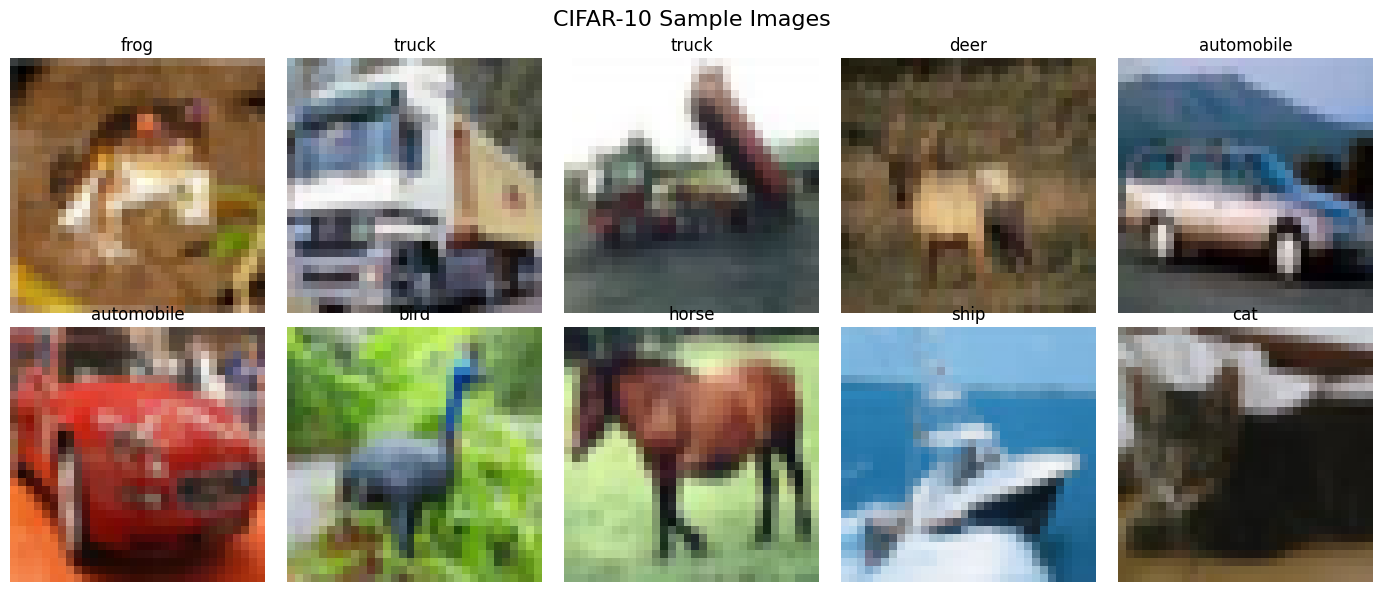

In [ ]:

classes = train_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    image = image * torch.tensor(
        [0.2470, 0.2435, 0.2616]
    ).view(3, 1, 1)

    image = image + torch.tensor(
        [0.4914, 0.4822, 0.4465]
    ).view(3, 1, 1)

    image = torch.clamp(image, 0, 1)

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:


train_labels = np.array(train_dataset.targets)

print("Label distribution:")

unique, counts = np.unique(train_labels, return_counts=True)

for label, count in zip(unique, counts):
    print(f"{label} ({classes[label]}): {count}")

Label distribution:
0 (airplane): 5000
1 (automobile): 5000
2 (bird): 5000
3 (cat): 5000
4 (deer): 5000
5 (dog): 5000
6 (frog): 5000
7 (horse): 5000
8 (ship): 5000
9 (truck): 5000


In [ ]:


def dirichlet_partition(
    labels,
    num_clients,
    num_classes,
    alpha,
    seed
):

    rng = np.random.default_rng(seed)

    client_indices = [
        []
        for _ in range(num_clients)
    ]

    for class_id in range(num_classes):

        class_indices = np.where(
            labels == class_id
        )[0]

        rng.shuffle(class_indices)

        proportions = rng.dirichlet(
            np.repeat(alpha, num_clients)
        )

        split_points = (
            np.cumsum(proportions)
            * len(class_indices)
        ).astype(int)

        split_points[-1] = len(
            class_indices
        )

        splits = np.split(
            class_indices,
            split_points[:-1]
        )

        for client_id, indices in enumerate(splits):

            client_indices[
                client_id
            ].extend(
                indices.tolist()
            )

    for client_id in range(num_clients):

        rng.shuffle(
            client_indices[client_id]
        )

    return client_indices

In [ ]:

client_data = dirichlet_partition(
    labels=train_labels,
    num_clients=NUM_CLIENTS,
    num_classes=NUM_CLASSES,
    alpha=NON_IID_ALPHA,
    seed=SEED
)


print(
    "Created",
    len(client_data),
    "clients."
)

for client_id in range(10):

    print(
        f"Client {client_id:02d}: "
        f"{len(client_data[client_id])} samples"
    )

Created 50 clients.
Client 00: 1605 samples
Client 01: 1703 samples
Client 02: 927 samples
Client 03: 639 samples
Client 04: 1261 samples
Client 05: 719 samples
Client 06: 505 samples
Client 07: 1954 samples
Client 08: 1022 samples
Client 09: 555 samples


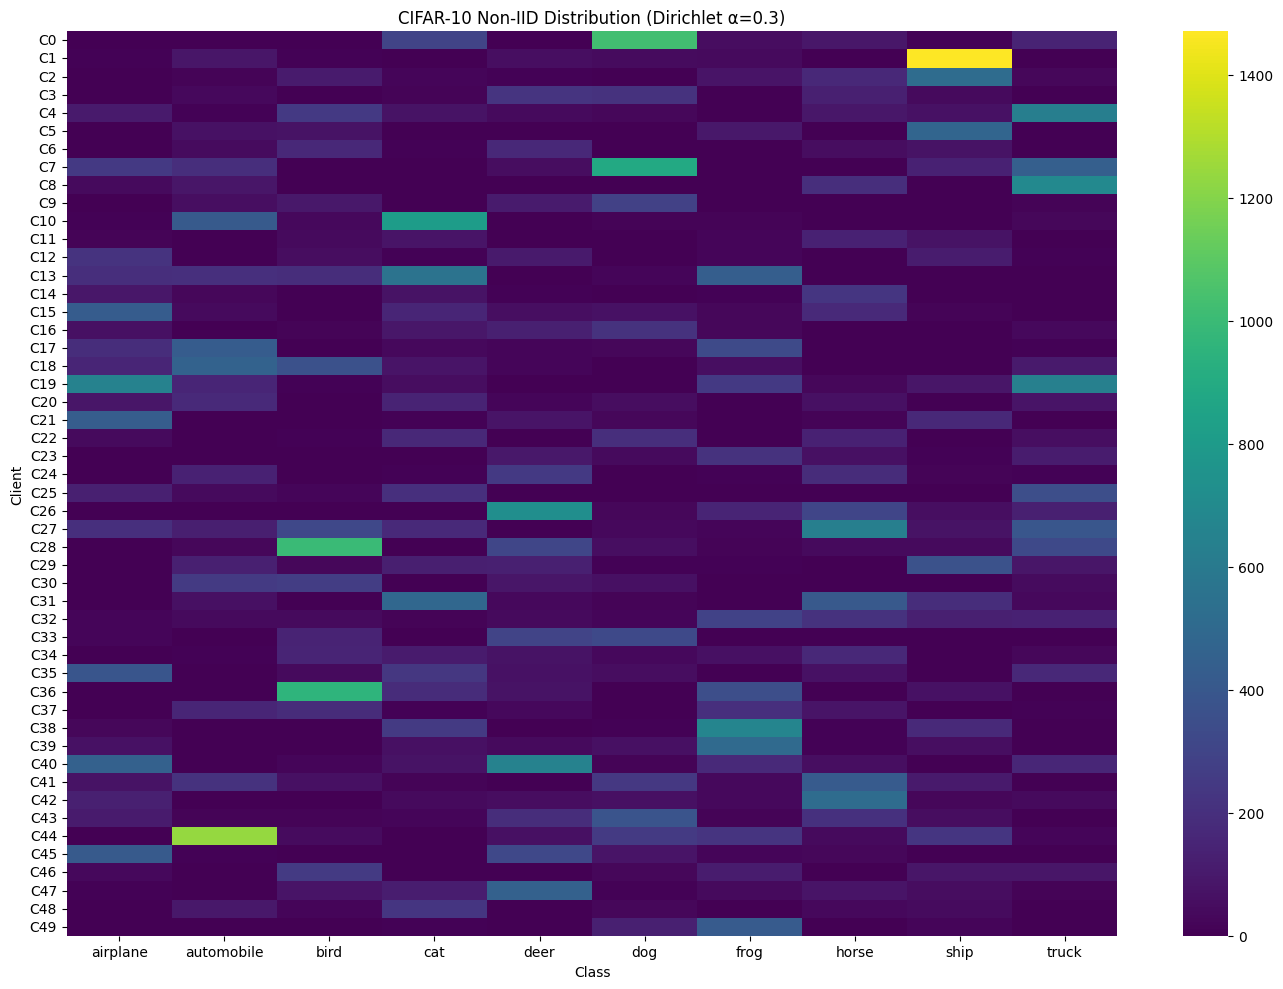

In [ ]:


client_class_distribution = np.zeros(
    (NUM_CLIENTS, NUM_CLASSES)
)


for client_id in range(NUM_CLIENTS):

    labels = train_labels[
        client_data[client_id]
    ]

    for class_id in range(NUM_CLASSES):

        client_class_distribution[
            client_id,
            class_id
        ] = np.sum(
            labels == class_id
        )


plt.figure(figsize=(14, 10))

sns.heatmap(
    client_class_distribution,
    cmap="viridis",
    xticklabels=classes,
    yticklabels=[
        f"C{i}"
        for i in range(NUM_CLIENTS)
    ]
)

plt.title(
    f"CIFAR-10 Non-IID Distribution "
    f"(Dirichlet α={NON_IID_ALPHA})"
)

plt.xlabel("Class")
plt.ylabel("Client")

plt.tight_layout()

plt.show()

In [ ]:

class ClientDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        indices
    ):

        self.base_dataset = base_dataset
        self.indices = indices


    def __len__(self):

        return len(self.indices)


    def __getitem__(self, index):

        return self.base_dataset[
            self.indices[index]
        ]

In [ ]:


def initialize_client_resources(
    num_clients,
    seed
):

    rng = np.random.default_rng(seed)

    resources = {}

    for client_id in range(num_clients):

        resources[client_id] = {

            "cpu": rng.uniform(
                CPU_MIN,
                CPU_MAX
            ),

            "battery": rng.uniform(
                BATTERY_MIN,
                BATTERY_MAX
            ),

            "bandwidth": rng.uniform(
                BANDWIDTH_MIN,
                BANDWIDTH_MAX
            ),

            "latency": rng.uniform(
                LATENCY_MIN,
                LATENCY_MAX
            ),

            "availability": rng.uniform(
                0.7,
                1.0
            )
        }

    return resources


client_resources = (
    initialize_client_resources(
        NUM_CLIENTS,
        SEED
    )
)


resource_df = pd.DataFrame.from_dict(
    client_resources,
    orient="index"
)

resource_df.index.name = "client"

display(
    resource_df.head()
)

,cpu,battery,bandwidth,latency,availability
client,,,,,
0,6.417692,55.110275,86.566802,145.526245,0.728253
1,7.829356,80.891176,79.676109,43.060454,0.835116
2,3.595586,94.141199,66.167186,168.097090,0.833024
3,2.590671,64.366783,11.062639,168.973611,0.889499
4,6.306614,48.362077,97.216312,180.761802,0.933515


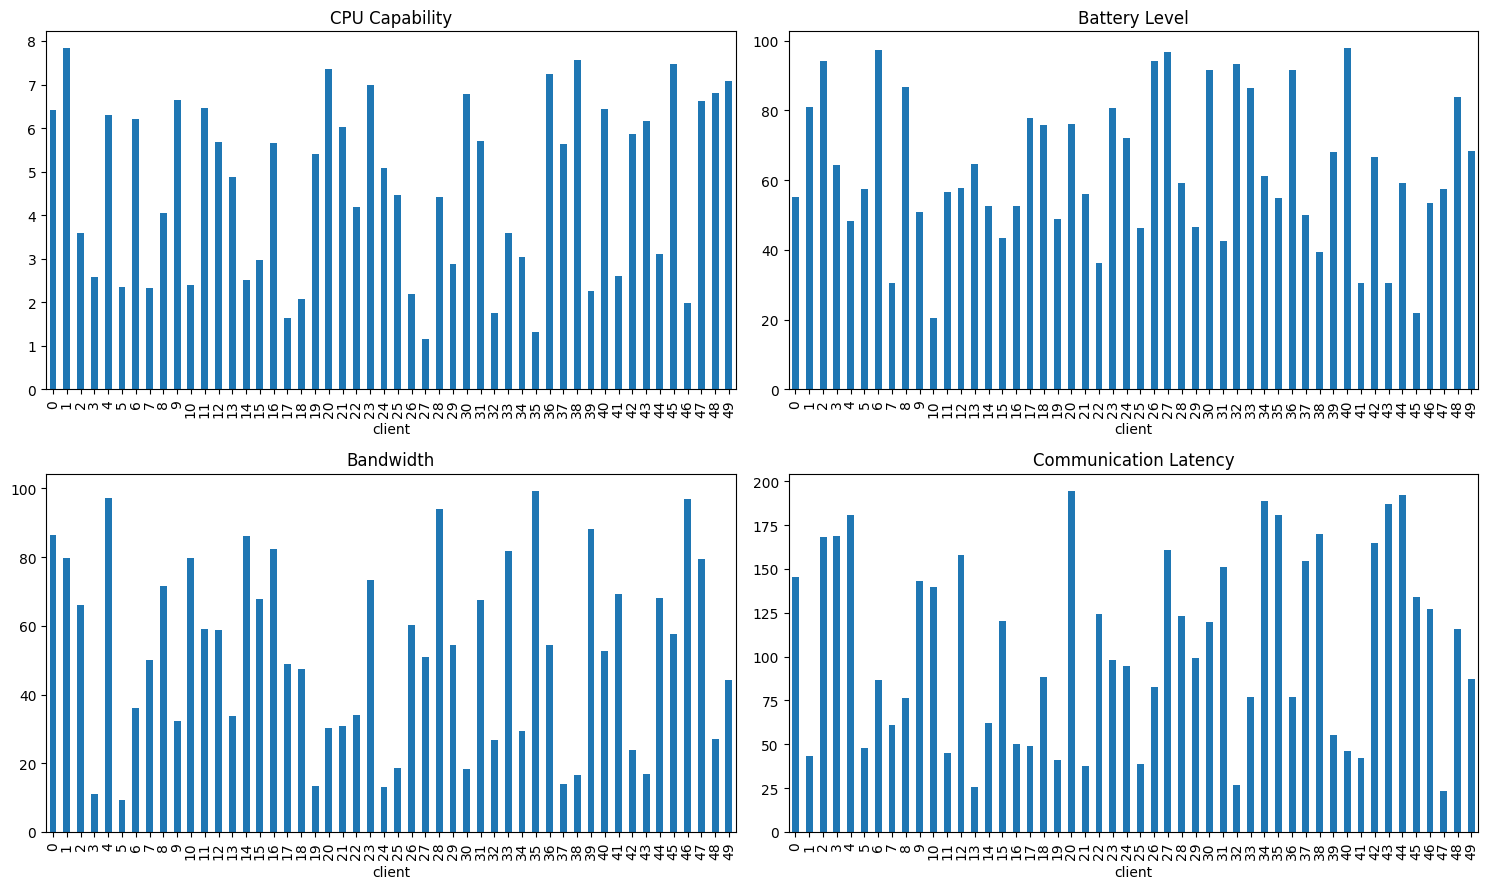

In [ ]:

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 9)
)


resource_df["cpu"].plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "CPU Capability"
)


resource_df["battery"].plot(
    kind="bar",
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Battery Level"
)


resource_df["bandwidth"].plot(
    kind="bar",
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Bandwidth"
)


resource_df["latency"].plot(
    kind="bar",
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Communication Latency"
)


plt.tight_layout()

plt.show()

In [ ]:


class CIFAR10CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 8 * 8,
                256
            ),

            nn.ReLU(),

            nn.Linear(
                256,
                NUM_CLASSES
            )
        )


    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)

In [ ]:


model = CIFAR10CNN().to(DEVICE)

dummy = torch.randn(
    8, 3, 32, 32
).to(DEVICE)

output = model(dummy)

print("Output shape:", output.shape)

Output shape: torch.Size([8, 10])


In [ ]:


def get_model_state(model):

    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


def load_model_state(
    model,
    state
):

    model.load_state_dict(state)


def fedavg(
    client_states,
    client_sizes
):

    total_samples = sum(
        client_sizes
    )

    weights = [
        size / total_samples
        for size in client_sizes
    ]

    global_state = {}

    for key in client_states[0].keys():

        global_state[key] = sum(
            weights[i]
            * client_states[i][key]
            for i in range(
                len(client_states)
            )
        )

    return global_state

In [ ]:

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


def evaluate_model(
    model,
    loader=test_loader
):

    model.eval()

    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0

    correct = 0

    total = 0


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = (
                outputs.argmax(dim=1)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)


    avg_loss = (
        total_loss / total
    )

    accuracy = (
        100.0 * correct / total
    )

    return avg_loss, accuracy

In [ ]:


def train_local_model(
    global_state,
    client_id,
    local_epochs,
    client_data,
    train_dataset,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE
):

    model = CIFAR10CNN().to(DEVICE)

    load_model_state(
        model,
        global_state
    )

    model.train()


    dataset = ClientDataset(
        train_dataset,
        client_data[client_id]
    )


    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )


    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )


    criterion = nn.CrossEntropyLoss()


    total_loss = 0.0

    total_correct = 0

    total_samples = 0


    start_time = time.time()


    for epoch in range(local_epochs):

        model.train()

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()


            total_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = (
                outputs.argmax(dim=1)
            )

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += (
                labels.size(0)
            )


    training_time = (
        time.time() - start_time
    )


    avg_loss = (
        total_loss
        / max(total_samples, 1)
    )


    local_accuracy = (
        total_correct
        / max(total_samples, 1)
    )


    return {
        "state": get_model_state(model),
        "loss": avg_loss,
        "accuracy": local_accuracy,
        "training_time": training_time,
        "samples": len(dataset)
    }

In [ ]:


def normalize_value(
    value,
    minimum,
    maximum
):

    return np.clip(
        (value - minimum)
        / (maximum - minimum + 1e-8),
        0.0,
        1.0
    )


def normalize_improvement(
    improvement,
    scale=0.10
):

    """
    Maps an accuracy improvement of approximately
    [-scale, +scale] into [0, 1].
    """

    return np.clip(
        (
            improvement + scale
        ) / (2 * scale),
        0.0,
        1.0
    )

In [ ]:


def initialize_client_history():

    history = {}

    for client_id in range(NUM_CLIENTS):

        history[client_id] = {

            "last_loss": 2.30,

            "last_accuracy": 0.10,

            "previous_accuracy": 0.10,

            "participation_count": 0,

            "last_epochs": 5,

            "last_training_time": 0.0,

            "last_energy": 0.0,

            "last_communication": 0.0
        }

    return history

In [ ]:


def update_client_resources(
    resources,
    selected_clients
):

    for client_id in range(NUM_CLIENTS):

        r = resources[client_id]


        if client_id in selected_clients:

            r["battery"] -= np.random.uniform(
                0.5,
                2.0
            )


        r["bandwidth"] += np.random.normal(
            0,
            3
        )

        r["latency"] += np.random.normal(
            0,
            5
        )

        r["cpu"] += np.random.normal(
            0,
            0.2
        )

        r["availability"] += np.random.normal(
            0,
            0.02
        )


        r["battery"] = np.clip(
            r["battery"],
            5,
            100
        )

        r["bandwidth"] = np.clip(
            r["bandwidth"],
            BANDWIDTH_MIN,
            BANDWIDTH_MAX
        )

        r["latency"] = np.clip(
            r["latency"],
            LATENCY_MIN,
            LATENCY_MAX
        )

        r["cpu"] = np.clip(
            r["cpu"],
            CPU_MIN,
            CPU_MAX
        )

        r["availability"] = np.clip(
            r["availability"],
            0.5,
            1.0
        )

In [ ]:


def calculate_data_diversity(
    client_id,
    client_data,
    train_labels
):

    labels = train_labels[
        client_data[client_id]
    ]

    unique_classes = len(
        np.unique(labels)
    )

    return (
        unique_classes
        / NUM_CLASSES
    )

In [ ]:


def build_client_state(
    client_id,
    client_data,
    train_labels,
    resources,
    history
):


    data_size = len(
        client_data[client_id]
    )

    max_data_size = max(
        len(indices)
        for indices in client_data
    )

    data_size_norm = (
        data_size
        / max_data_size
    )


    diversity = calculate_data_diversity(
        client_id,
        client_data,
        train_labels
    )


    h = history[client_id]


    r = resources[client_id]


    cpu = normalize_value(
        r["cpu"],
        CPU_MIN,
        CPU_MAX
    )

    battery = normalize_value(
        r["battery"],
        5,
        100
    )

    bandwidth = normalize_value(
        r["bandwidth"],
        BANDWIDTH_MIN,
        BANDWIDTH_MAX
    )

    latency = normalize_value(
        r["latency"],
        LATENCY_MIN,
        LATENCY_MAX
    )


    participation = (
        h["participation_count"]
        / max(NUM_ROUNDS, 1)
    )

    last_epochs = (
        h["last_epochs"]
        / LOCAL_EPOCH_MAX
    )

    last_time = normalize_value(
        h["last_training_time"],
        0,
        30
    )

    last_energy = normalize_value(
        h["last_energy"],
        0,
        30
    )

    last_communication = normalize_value(
        h["last_communication"],
        0,
        10
    )


    state = np.array([

        data_size_norm,
        diversity,
        h["last_loss"],
        h["last_accuracy"],

        cpu,
        battery,
        bandwidth,
        latency,
        r["availability"],

        participation,
        last_epochs,
        last_time,
        last_energy,
        last_communication

    ], dtype=np.float32)


    return state

In [ ]:


class ReplayBuffer:

    def __init__(self, capacity):

        self.buffer = deque(
            maxlen=capacity
        )


    def push(
        self,
        state,
        action,
        reward,
        next_state,
        done
    ):

        self.buffer.append(
            (
                np.asarray(
                    state,
                    dtype=np.float32
                ),

                int(action),

                float(reward),

                np.asarray(
                    next_state,
                    dtype=np.float32
                ),

                float(done)
            )
        )


    def sample(
        self,
        batch_size
    ):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(
            *batch
        )

        return (
            np.asarray(states),
            np.asarray(actions),
            np.asarray(rewards),
            np.asarray(next_states),
            np.asarray(dones)
        )


    def __len__(self):

        return len(self.buffer)

In [ ]:


class DQNNetwork(nn.Module):

    def __init__(
        self,
        state_dim,
        action_dim
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                state_dim,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                action_dim
            )
        )


    def forward(self, x):

        return self.network(x)

In [ ]:


class DQNAgent:

    def __init__(
        self,
        state_dim,
        action_dim,
        double_dqn=False
    ):

        self.state_dim = state_dim

        self.action_dim = action_dim

        self.double_dqn = double_dqn


        self.gamma = RL_GAMMA

        self.epsilon = EPSILON_START

        self.epsilon_end = EPSILON_END

        self.epsilon_decay = EPSILON_DECAY


        self.policy_net = DQNNetwork(
            state_dim,
            action_dim
        ).to(DEVICE)


        self.target_net = DQNNetwork(
            state_dim,
            action_dim
        ).to(DEVICE)


        self.target_net.load_state_dict(
            self.policy_net.state_dict()
        )

        self.target_net.eval()


        self.optimizer = optim.Adam(
            self.policy_net.parameters(),
            lr=RL_LR
        )


        self.replay_buffer = ReplayBuffer(
            REPLAY_CAPACITY
        )


    def select_action(
        self,
        state,
        training=True
    ):

        if (
            training
            and random.random()
            < self.epsilon
        ):

            return random.randrange(
                self.action_dim
            )


        state_tensor = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0).to(DEVICE)


        with torch.no_grad():

            q_values = self.policy_net(
                state_tensor
            )


        return int(
            q_values.argmax(
                dim=1
            ).item()
        )


    def train_step(self):

        if len(
            self.replay_buffer
        ) < RL_BATCH_SIZE:

            return None


        (
            states,
            actions,
            rewards,
            next_states,
            dones
        ) = self.replay_buffer.sample(
            RL_BATCH_SIZE
        )


        states = torch.tensor(
            states,
            dtype=torch.float32,
            device=DEVICE
        )

        actions = torch.tensor(
            actions,
            dtype=torch.long,
            device=DEVICE
        )

        rewards = torch.tensor(
            rewards,
            dtype=torch.float32,
            device=DEVICE
        )

        next_states = torch.tensor(
            next_states,
            dtype=torch.float32,
            device=DEVICE
        )

        dones = torch.tensor(
            dones,
            dtype=torch.float32,
            device=DEVICE
        )


        current_q = (
            self.policy_net(states)
            .gather(
                1,
                actions.unsqueeze(1)
            )
            .squeeze(1)
        )


        with torch.no_grad():

            if self.double_dqn:

                next_actions = (
                    self.policy_net(
                        next_states
                    )
                    .argmax(
                        dim=1,
                        keepdim=True
                    )
                )

                next_q = (
                    self.target_net(
                        next_states
                    )
                    .gather(
                        1,
                        next_actions
                    )
                    .squeeze(1)
                )

            else:

                next_q = (
                    self.target_net(
                        next_states
                    )
                    .max(
                        dim=1
                    )
                    .values
                )


            target_q = (
                rewards
                + self.gamma
                * next_q
                * (1 - dones)
            )


        loss = F.smooth_l1_loss(
            current_q,
            target_q
        )


        self.optimizer.zero_grad()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            self.policy_net.parameters(),
            5.0
        )

        self.optimizer.step()


        return float(
            loss.item()
        )


    def update_target(self):

        self.target_net.load_state_dict(
            self.policy_net.state_dict()
        )


    def decay_epsilon(self):

        self.epsilon = max(
            self.epsilon_end,
            self.epsilon
            * self.epsilon_decay
        )

In [ ]:


def estimate_communication_cost(
    client_id,
    resources
):

    r = resources[client_id]

    bandwidth = r["bandwidth"]

    latency = r["latency"]


    # Model upload time
    transmission_time = (
        MODEL_SIZE_MB * 8
        / max(bandwidth, 1e-6)
    )


    latency_time = (
        latency / 1000.0
    )


    total_time = (
        transmission_time
        + latency_time
    )


    return total_time


def estimate_energy_cost(
    client_id,
    epochs,
    training_time,
    resources
):

    cpu = resources[
        client_id
    ]["cpu"]


    energy = (
        training_time
        / max(cpu, 0.1)
    )


    return energy

In [ ]:

def normalize_time(time_value):

    return np.clip(
        time_value / 30.0,
        0.0,
        1.0
    )


def normalize_communication(
    communication
):

    return np.clip(
        communication / 10.0,
        0.0,
        1.0
    )


def normalize_energy(energy):

    return np.clip(
        energy / 30.0,
        0.0,
        1.0
    )

In [ ]:


def calculate_fairness(
    participation_counts
):

    counts = np.asarray(
        participation_counts,
        dtype=np.float64
    )


    if np.sum(counts) == 0:

        return 1.0


    numerator = (
        np.sum(counts) ** 2
    )


    denominator = (
        len(counts)
        * np.sum(counts ** 2)
        + 1e-8
    )


    fairness = (
        numerator
        / denominator
    )


    return float(
        np.clip(
            fairness,
            0,
            1
        )
    )

In [ ]:


def calculate_high_level_reward(

    accuracy_improvement,

    data_utility,

    total_training_time,

    total_communication,

    total_energy,

    fairness

):


    accuracy_component = np.clip(
        accuracy_improvement / 0.10,
        -1.0,
        1.0
    )


    data_component = np.clip(
        data_utility,
        0,
        1
    )


    time_component = normalize_time(
        total_training_time
    )


    communication_component = (
        normalize_communication(
            total_communication
        )
    )


    energy_component = normalize_energy(
        total_energy
    )


    reward = (

        W_GLOBAL_ACCURACY
        * accuracy_component

        + W_DATA_UTILITY
        * data_component

        - W_TIME
        * time_component

        - W_COMMUNICATION
        * communication_component

        - W_ENERGY
        * energy_component

        + W_FAIRNESS
        * fairness

    )


    return float(reward)

In [ ]:


def calculate_low_level_reward(

    local_accuracy_improvement,

    training_time,

    energy,

    communication

):

    accuracy_component = np.clip(
        local_accuracy_improvement
        / 0.10,
        -1.0,
        1.0
    )


    time_component = normalize_time(
        training_time
    )


    energy_component = normalize_energy(
        energy
    )


    communication_component = (
        normalize_communication(
            communication
        )
    )


    reward = (

        W_LOCAL_ACCURACY
        * accuracy_component

        - W_LOCAL_TIME
        * time_component

        - W_LOCAL_ENERGY
        * energy_component

        - W_LOCAL_COMMUNICATION
        * communication_component

    )


    return float(reward)

In [ ]:


def initialize_experiment(
    seed=42
):

    set_seed(seed)


    resources = (
        initialize_client_resources(
            NUM_CLIENTS,
            seed
        )
    )


    history = (
        initialize_client_history()
    )


    global_model = (
        CIFAR10CNN()
        .to(DEVICE)
    )


    return (
        global_model,
        resources,
        history
    )

In [ ]:

STATE_DIM = 14
CLIENT_ACTION_DIM = 2
EPOCH_ACTION_DIM = 5
COUNT_ACTIONS = [5, 8, 10, 12, 15, 20]
COUNT_STATE_DIM = 12
COUNT_ACTION_DIM = len(COUNT_ACTIONS)
RL_BATCH_SIZE = 8
EPISODE_LENGTH = 5
SUCCESS_ACCURACY_THRESHOLD = 50.0
SUCCESS_MIN_MEAN_REWARD = 0.0
CONVERGENCE_ACCURACY_THRESHOLD = 50.0
CONVERGENCE_CONSECUTIVE_ROUNDS = 3
PPO_LR = 3e-4
PPO_CLIP = 0.2
PPO_UPDATE_EPOCHS = 4
PPO_ENTROPY_COEF = 0.01
PPO_VALUE_COEF = 0.5
PPO_MINIBATCH_SIZE = 32
QL_ALPHA = 0.15
QL_EPSILON_START = 1.0
QL_EPSILON_END = 0.05
QL_EPSILON_DECAY = 0.97
QL_GAMMA = RL_GAMMA
print('Seven-method 50-round comparison settings loaded.')


Seven-method 50-round comparison settings loaded.


In [ ]:


class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh()
        )
        self.actor = nn.Linear(128, action_dim)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        z = self.shared(x)
        return self.actor(z), self.critic(z).squeeze(-1)


class PPOAgent:
    def __init__(self, state_dim, action_dim):
        self.model = ActorCritic(state_dim, action_dim).to(DEVICE)
        self.optimizer = optim.Adam(self.model.parameters(), lr=PPO_LR)
        self.memory = []

    def select_action(self, state, training=True, action_mask=None):
        x = torch.as_tensor(
            state, dtype=torch.float32, device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            logits, value = self.model(x)

            if action_mask is not None:
                mask = torch.as_tensor(
                    action_mask, dtype=torch.bool, device=DEVICE
                ).unsqueeze(0)

                if not mask.any():
                    mask[0, 0] = True
                logits = logits.masked_fill(~mask, -1e9)

            dist = torch.distributions.Categorical(logits=logits)
            action = dist.sample() if training else torch.argmax(logits, dim=-1)
            log_prob = dist.log_prob(action)

        return int(action.item()), float(log_prob.item()), float(value.item())

    def store(self, state, action, log_prob, reward, next_state, done):
        self.memory.append((
            np.asarray(state, dtype=np.float32),
            int(action),
            float(log_prob),
            float(reward),
            np.asarray(next_state, dtype=np.float32),
            float(done)
        ))

    def update(self):
        if len(self.memory) < 2:
            return None

        states, actions, old_log_probs, rewards, next_states, dones = zip(*self.memory)

        states = torch.as_tensor(np.asarray(states), dtype=torch.float32, device=DEVICE)
        actions = torch.as_tensor(actions, dtype=torch.long, device=DEVICE)
        old_log_probs = torch.as_tensor(old_log_probs, dtype=torch.float32, device=DEVICE)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE)
        next_states = torch.as_tensor(np.asarray(next_states), dtype=torch.float32, device=DEVICE)
        dones = torch.as_tensor(dones, dtype=torch.float32, device=DEVICE)

        with torch.no_grad():
            _, values = self.model(states)
            _, next_values = self.model(next_states)
            td_targets = rewards + RL_GAMMA * next_values * (1.0 - dones)
            advantages = td_targets - values
            advantages = (advantages - advantages.mean()) / (
                advantages.std(unbiased=False) + 1e-8
            )

        n = len(self.memory)
        losses = []

        for _ in range(PPO_UPDATE_EPOCHS):
            order = torch.randperm(n, device=DEVICE)
            for start in range(0, n, PPO_MINIBATCH_SIZE):
                ids = order[start:start + PPO_MINIBATCH_SIZE]
                logits, predicted_values = self.model(states[ids])
                dist = torch.distributions.Categorical(logits=logits)
                new_log_probs = dist.log_prob(actions[ids])
                entropy = dist.entropy().mean()

                ratios = torch.exp(new_log_probs - old_log_probs[ids])
                unclipped = ratios * advantages[ids]
                clipped = torch.clamp(
                    ratios, 1.0 - PPO_CLIP, 1.0 + PPO_CLIP
                ) * advantages[ids]

                policy_loss = -torch.min(unclipped, clipped).mean()
                value_loss = F.mse_loss(predicted_values, td_targets[ids])
                loss = (
                    policy_loss
                    + PPO_VALUE_COEF * value_loss
                    - PPO_ENTROPY_COEF * entropy
                )

                self.optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 0.5)
                self.optimizer.step()
                losses.append(float(loss.item()))

        self.memory.clear()
        return float(np.mean(losses)) if losses else None


def make_agent(algorithm, state_dim, action_dim):
    algorithm = algorithm.upper()
    if algorithm == "PPO":
        return PPOAgent(state_dim, action_dim)
    if algorithm in ("DQN", "DDQN"):
        return DQNAgent(
            state_dim=state_dim,
            action_dim=action_dim,
            double_dqn=(algorithm == "DDQN")
        )
    raise ValueError(f"Unsupported algorithm: {algorithm}")


In [ ]:


def build_count_state(resources, history, global_accuracy, round_idx, total_rounds):
    vals = list(resources.values())
    cpu = np.asarray([v["cpu"] for v in vals], dtype=np.float32)
    battery = np.asarray([v["battery"] for v in vals], dtype=np.float32)
    bandwidth = np.asarray([v["bandwidth"] for v in vals], dtype=np.float32)
    latency = np.asarray([v["latency"] for v in vals], dtype=np.float32)
    availability = np.asarray([v["availability"] for v in vals], dtype=np.float32)
    participation = np.asarray(
        [history[i]["participation_count"] for i in range(NUM_CLIENTS)],
        dtype=np.float32
    )
    last_acc = np.asarray(
        [history[i]["last_accuracy"] for i in range(NUM_CLIENTS)],
        dtype=np.float32
    )

    state = np.asarray([
        round_idx / max(total_rounds, 1),
        global_accuracy / 100.0,
        cpu.mean() / CPU_MAX,
        cpu.std() / CPU_MAX,
        battery.mean() / 100.0,
        bandwidth.mean() / BANDWIDTH_MAX,
        bandwidth.std() / BANDWIDTH_MAX,
        latency.mean() / LATENCY_MAX,
        availability.mean(),
        participation.mean() / max(total_rounds, 1),
        calculate_fairness(participation),
        last_acc.mean()
    ], dtype=np.float32)

    return np.nan_to_num(state, nan=0.0, posinf=1.0, neginf=0.0)


def choose_count(agent, algorithm, state, available_count, training=True):
    mask = np.asarray(
        [n <= available_count for n in COUNT_ACTIONS],
        dtype=bool
    )
    if not mask.any():
        mask[0] = True

    if algorithm == "PPO":
        action, log_prob, value = agent.select_action(
            state, training=training, action_mask=mask
        )
        requested = COUNT_ACTIONS[action]
        actual = min(requested, available_count)
        return action, requested, actual, log_prob, value

    valid = np.flatnonzero(mask)
    if algorithm == "QLEARNING":
        action = agent.select_action(state, training=training)
        if action not in valid:
            action = int(valid[np.argmax(agent.q_values(state)[valid])])
        requested = COUNT_ACTIONS[action]
        return action, requested, min(requested, available_count), None, None
    if training and random.random() < agent.epsilon:
        action = int(random.choice(valid.tolist()))
    else:
        x = torch.as_tensor(
            state, dtype=torch.float32, device=DEVICE
        ).unsqueeze(0)
        with torch.no_grad():
            q = agent.policy_net(x)[0].detach().cpu().numpy()
        action = int(max(valid, key=lambda i: q[i]))

    requested = COUNT_ACTIONS[action]
    return action, requested, min(requested, available_count), None, None


def build_selection_matrix(selected_history):
    matrix = np.zeros((NUM_CLIENTS, len(selected_history)))
    for r, clients in enumerate(selected_history):
        for cid in clients:
            matrix[cid, r] = 1
    return matrix


def build_epoch_matrix(epoch_history):
    matrix = np.zeros((NUM_CLIENTS, len(epoch_history)))
    for r, assignments in enumerate(epoch_history):
        for cid, epochs in assignments.items():
            matrix[cid, r] = epochs
    return matrix


In [ ]:

class QLearningAgent:
    def __init__(self, state_dim, action_dim):
        self.state_dim, self.action_dim = state_dim, action_dim
        self.q = defaultdict(lambda: np.zeros(action_dim, dtype=np.float32))
        self.alpha, self.gamma = QL_ALPHA, QL_GAMMA
        self.epsilon = QL_EPSILON_START
        self.memory = deque(maxlen=REPLAY_CAPACITY)
    def key(self, state):
        x = np.asarray(state, dtype=np.float32)
        return tuple(np.clip(np.floor(np.nan_to_num(x) * 4), 0, 3).astype(int).tolist())
    def q_values(self, state): return self.q[self.key(state)]
    def select_action(self, state, training=True):
        if training and random.random() < self.epsilon: return random.randrange(self.action_dim)
        return int(np.argmax(self.q_values(state)))
    def push(self, state, action, reward, next_state, done):
        self.memory.append((self.key(state), int(action), float(reward), self.key(next_state), bool(done)))
    def train_step(self):
        if not self.memory: return None
        batch = random.sample(self.memory, min(RL_BATCH_SIZE, len(self.memory)))
        losses=[]
        for state, action, reward, nxt, done in batch:
            target = reward if done else reward + self.gamma * float(np.max(self.q[nxt]))
            old = self.q[state][action]
            self.q[state][action] += self.alpha * (target-old)
            losses.append((target-old)**2)
        return float(np.mean(losses))
    def decay_epsilon(self): self.epsilon=max(QL_EPSILON_END, self.epsilon*QL_EPSILON_DECAY)
    def update_target(self): pass

def make_agent(algorithm, state_dim, action_dim):
    algorithm = algorithm.upper()
    if algorithm == 'PPO': return PPOAgent(state_dim, action_dim)
    if algorithm == 'QLEARNING': return QLearningAgent(state_dim, action_dim)
    if algorithm in ('DQN','DDQN'):
        return DQNAgent(state_dim, action_dim, double_dqn=(algorithm == 'DDQN'))
    raise ValueError(f'Unsupported algorithm: {algorithm}')



In [ ]:

METHODS = {
    "QLEARNING3": ("QLEARNING", "QLEARNING", "QLEARNING"),
    "DQN3": ("DQN", "DQN", "DQN"),
    "DDQN3": ("DDQN", "DDQN", "DDQN"),
    "PPO3": ("PPO", "PPO", "PPO"),
    "DQN_PPO": ("DQN", "DQN", "PPO"),
    "PPO_DQN": ("PPO", "DQN", "DQN")
}

def _agent_score(agent, algo, state):
    if algo == "PPO":
        x=torch.as_tensor(state,dtype=torch.float32,device=DEVICE).unsqueeze(0)
        with torch.no_grad(): logits,_=agent.model(x)
        probs=torch.softmax(logits,dim=-1)[0]
        return float((probs[1]-probs[0]).item())
    if algo == "QLEARNING": return float(agent.q_values(state)[1]-agent.q_values(state)[0])
    x=torch.as_tensor(state,dtype=torch.float32,device=DEVICE).unsqueeze(0)
    with torch.no_grad(): q=agent.policy_net(x)[0]
    return float((q[1]-q[0]).item())

def run_three_decision_experiment(method="DQN3", num_rounds=50, seed=42, verbose=True):
    method=method.upper()
    if method not in list(METHODS)+["FEDAVG"]: raise ValueError(method)
    set_seed(seed)
    global_model, resources, history=initialize_experiment(seed)
    global_state=get_model_state(global_model)
    if method == "FEDAVG":
        count_algo=selection_algo=epoch_algo="FIXED"
        count_agent=selection_agent=epoch_agent=None
    else:
        count_algo,selection_algo,epoch_algo=METHODS[method]

        set_seed(seed + {"QLEARNING3":101,"DQN3":201,"DDQN3":301,"PPO3":401,"DQN_PPO":501,"PPO_DQN":601}[method])
        count_agent=make_agent(count_algo,COUNT_STATE_DIM,COUNT_ACTION_DIM)
        selection_agent=make_agent(selection_algo,STATE_DIM,CLIENT_ACTION_DIM)
        epoch_agent=make_agent(epoch_algo,STATE_DIM,EPOCH_ACTION_DIM)

        random.seed(seed+9000); np.random.seed(seed+9000)
    results=[]; selected_history=[]; epoch_history=[]; count_history=[]
    previous_global_accuracy=10.0; episode_return=0.0; episode_rewards=[]
    convergence_hits=0; convergence_round=None; cumulative_interactions=0
    for round_idx in range(num_rounds):
        round_start=time.time(); rl_start=time.time()
        client_states={cid:build_client_state(cid,client_data,train_labels,resources,history) for cid in range(NUM_CLIENTS)}
        available=[cid for cid in range(NUM_CLIENTS) if random.random()<resources[cid]["availability"] and resources[cid]["battery"]>5.0]
        if not available: available=[max(resources,key=lambda cid:resources[cid]["availability"])]
        count_state=build_count_state(resources,history,previous_global_accuracy,round_idx,num_rounds)
        count_log_prob=None; count_action=None
        if method == "FEDAVG": requested_count=10; actual_count=min(requested_count,len(available))
        else:
            if count_algo=="PPO":
                mask=np.asarray([n<=len(available) for n in COUNT_ACTIONS],dtype=bool)
                count_action,count_log_prob,_=count_agent.select_action(count_state,True,mask)
                requested_count=COUNT_ACTIONS[count_action]; actual_count=min(requested_count,len(available))
            else:
                count_action=choose_count(count_agent,count_algo,count_state,len(available),True)[0]
                requested_count=COUNT_ACTIONS[count_action]; actual_count=min(requested_count,len(available))
        if method=="FEDAVG":
            selected=random.sample(available,actual_count)
        else:
            scored=[]
            for cid in available:
                score=_agent_score(selection_agent,selection_algo,client_states[cid])
                if selection_algo in ("DQN","DDQN","QLEARNING") and random.random()<selection_agent.epsilon:
                    score += float(np.random.normal(0,0.5))
                scored.append((cid,score))
            scored.sort(key=lambda z:z[1],reverse=True)
            selected=[cid for cid,_ in scored[:actual_count]]
        epoch_assignments={}; epoch_info={}
        for cid in selected:
            if method=="FEDAVG": action=1; epoch_assignments[cid]=2; epoch_info[cid]=None
            elif epoch_algo=="PPO":
                action,lp,val=epoch_agent.select_action(client_states[cid],True); epoch_info[cid]=(action,lp,val); epoch_assignments[cid]=LOCAL_EPOCH_MIN+action
            else:
                action=epoch_agent.select_action(client_states[cid],True); epoch_info[cid]=None; epoch_assignments[cid]=LOCAL_EPOCH_MIN+action
        rl_decision_time=time.time()-rl_start
        local_states=[]; local_sizes=[]; utilities=[]; local_rewards={}
        compute=comm=energy=0.0
        for cid in selected:
            epochs=epoch_assignments[cid]; old_acc=history[cid]["last_accuracy"]
            lr=train_local_model(global_state,cid,epochs,client_data,train_dataset)
            local_states.append(lr["state"]); local_sizes.append(lr["samples"])
            cp=estimate_communication_cost(cid,resources); ep=estimate_energy_cost(cid,epochs,lr["training_time"],resources)
            compute+=lr["training_time"]; comm+=cp; energy+=ep
            utility=calculate_data_diversity(cid,client_data,train_labels); utilities.append(utility)
            local_reward=calculate_low_level_reward(lr["accuracy"]-old_acc,lr["training_time"],ep,cp); local_rewards[cid]=float(local_reward)
            history[cid].update({"previous_accuracy":old_acc,"last_accuracy":lr["accuracy"],"last_loss":lr["loss"],"last_epochs":epochs,"last_training_time":lr["training_time"],"last_energy":ep,"last_communication":cp,"participation_count":history[cid]["participation_count"]+1})
            nxt=build_client_state(cid,client_data,train_labels,resources,history); a=epochs-LOCAL_EPOCH_MIN
            if method!="FEDAVG":
                if epoch_algo=="PPO":
                    _,lp,_=epoch_info[cid]; epoch_agent.store(client_states[cid],a,lp,local_reward,nxt,round_idx==num_rounds-1)
                elif epoch_algo=="QLEARNING": epoch_agent.push(client_states[cid],a,local_reward,nxt,round_idx==num_rounds-1)
                else: epoch_agent.replay_buffer.push(client_states[cid],a,local_reward,nxt,round_idx==num_rounds-1)
        if local_states:
            global_state=fedavg(local_states,local_sizes); load_model_state(global_model,global_state)
        test_loss,test_acc=evaluate_model(global_model)
        fairness=calculate_fairness([history[i]["participation_count"] for i in range(NUM_CLIENTS)])
        mean_utility=float(np.mean(utilities)) if utilities else 0.0
        high_reward=calculate_high_level_reward((test_acc-previous_global_accuracy)/100.0,mean_utility,compute,comm,energy,fairness)
        selected_set=set(selected); contribution={cid:0.5*np.clip((history[cid]["last_accuracy"]-history[cid]["previous_accuracy"])/0.10,-1,1)+0.2*np.clip(calculate_data_diversity(cid,client_data,train_labels),0,1) for cid in selected}
        mean_contrib=float(np.mean(list(contribution.values()))) if contribution else 0.0
        if method!="FEDAVG":
            for cid in range(NUM_CLIENTS):
                nxt=build_client_state(cid,client_data,train_labels,resources,history); a=int(cid in selected_set)
                rew=(high_reward+0.25*(contribution[cid]-mean_contrib)) if a else 0.0
                if selection_algo=="PPO":
                    x=torch.as_tensor(client_states[cid],dtype=torch.float32,device=DEVICE).unsqueeze(0)
                    with torch.no_grad(): logits,_=selection_agent.model(x)
                    dist=torch.distributions.Categorical(logits=logits); lp=float(dist.log_prob(torch.tensor([a],device=DEVICE)).item())
                    selection_agent.store(client_states[cid],a,lp,float(rew),nxt,round_idx==num_rounds-1)
                elif selection_algo=="QLEARNING": selection_agent.push(client_states[cid],a,float(rew),nxt,round_idx==num_rounds-1)
                else: selection_agent.replay_buffer.push(client_states[cid],a,float(rew),nxt,round_idx==num_rounds-1)
            nxt_count=build_count_state(resources,history,test_acc,round_idx+1,num_rounds)
            if count_algo=="PPO": count_agent.store(count_state,count_action,count_log_prob,high_reward,nxt_count,round_idx==num_rounds-1)
            elif count_algo=="QLEARNING": count_agent.push(count_state,count_action,high_reward,nxt_count,round_idx==num_rounds-1)
            else: count_agent.replay_buffer.push(count_state,count_action,high_reward,nxt_count,round_idx==num_rounds-1)
        update_start=time.time(); losses={"count":None,"selection":None,"epoch":None}
        if method!="FEDAVG":
            for name,agent,algo in [("count",count_agent,count_algo),("selection",selection_agent,selection_algo),("epoch",epoch_agent,epoch_algo)]:
                if algo=="PPO":
                    if (round_idx+1)%EPISODE_LENGTH==0 or round_idx==num_rounds-1: losses[name]=agent.update()
                else:
                    losses[name]=agent.train_step()
                    if algo in ("DQN","DDQN") and (round_idx+1)%TARGET_UPDATE_FREQ==0: agent.update_target()
                    agent.decay_epsilon()
        rl_update_time=time.time()-update_start
        update_client_resources(resources,selected)
        episode_return+=float(high_reward); episode_rewards.append(float(high_reward))
        episode_end=(round_idx+1)%EPISODE_LENGTH==0 or round_idx==num_rounds-1
        ep_return=episode_return if episode_end else np.nan
        ep_success=int(test_acc>=SUCCESS_ACCURACY_THRESHOLD and np.mean(episode_rewards)>SUCCESS_MIN_MEAN_REWARD) if episode_end else np.nan
        if episode_end: episode_return=0.0; episode_rewards=[]
        convergence_hits=convergence_hits+1 if test_acc>=CONVERGENCE_ACCURACY_THRESHOLD else 0
        if convergence_round is None and convergence_hits>=CONVERGENCE_CONSECUTIVE_ROUNDS: convergence_round=round_idx+1
        cumulative_interactions+=(1+NUM_CLIENTS+len(selected))*3 if method!="FEDAVG" else 0
        row={"round":round_idx+1,"accuracy":float(test_acc),"loss":float(test_loss),"reward":float(high_reward),"cumulative_reward":float(sum(x["reward"] for x in results)+high_reward),"episode_return_at_end":ep_return,"episode_success_at_end":ep_success,"requested_count":int(requested_count),"selected_count":len(selected),"available_count":len(available),"mean_epochs":float(np.mean(list(epoch_assignments.values()))),"fairness":float(fairness),"data_utility":mean_utility,"sum_local_compute_time_sec":compute,"communication_time_proxy_sec":comm,"energy_proxy_units":energy,"rl_decision_time_sec":rl_decision_time if method!="FEDAVG" else 0.0,"rl_update_time_sec":rl_update_time,"cumulative_agent_interactions":cumulative_interactions,"count_loss":losses["count"],"selection_loss":losses["selection"],"epoch_loss":losses["epoch"],"convergence_round":convergence_round,"wall_time_sec":time.time()-round_start}
        results.append(row); selected_history.append(selected.copy()); epoch_history.append(epoch_assignments.copy()); count_history.append(int(requested_count)); previous_global_accuracy=test_acc
        if verbose: print(f"{method} | Round {round_idx+1:02d}/{num_rounds} | Acc={test_acc:.2f}% | Count={len(selected)} | MeanEpoch={row['mean_epochs']:.2f} | Reward={high_reward:.4f}")
    df=pd.DataFrame(results); eps=df["episode_return_at_end"].dropna(); succ=df["episode_success_at_end"].dropna()
    summary={"method":method,"final_accuracy":float(df.accuracy.iloc[-1]),"best_accuracy":float(df.accuracy.max()),"mean_episodic_return":float(eps.mean()) if len(eps) else np.nan,"success_rate_percent":float(100*succ.mean()) if len(succ) else np.nan,"convergence_round":convergence_round,"total_reward":float(df.reward.sum()),"total_rl_decision_time_sec":float(df.rl_decision_time_sec.sum()),"total_rl_update_time_sec":float(df.rl_update_time_sec.sum()),"total_local_compute_time_sec":float(df.sum_local_compute_time_sec.sum()),"total_communication_time_proxy_sec":float(df.communication_time_proxy_sec.sum()),"total_energy_proxy_units":float(df.energy_proxy_units.sum()),"mean_fairness":float(df.fairness.mean()),"sample_efficiency_final_reward_per_interaction":float(df.reward.sum()/max(cumulative_interactions,1)),"cumulative_accuracy_regret_vs_fedavg":np.nan}
    return {"method":method,"results":df,"summary":summary,"final_model_state":copy.deepcopy(global_state),"selected_history":selected_history,"epoch_history":epoch_history,"count_history":count_history}


In [ ]:
smoke=run_three_decision_experiment('DDQN3',num_rounds=2,seed=42,verbose=True)
display(smoke['results']); display(pd.DataFrame([smoke['summary']]))


DDQN3 | Round 01/2 | Acc=28.34% | Count=10 | MeanEpoch=3.60 | Reward=0.4283
DDQN3 | Round 02/2 | Acc=20.26% | Count=5 | MeanEpoch=3.80 | Reward=-0.3005


,round,accuracy,loss,reward,cumulative_reward,episode_return_at_end,episode_success_at_end,requested_count,selected_count,available_count,...,communication_time_proxy_sec,energy_proxy_units,rl_decision_time_sec,rl_update_time_sec,cumulative_agent_interactions,count_loss,selection_loss,epoch_loss,convergence_round,wall_time_sec
0,1,28.34,2.207373,0.428314,0.428314,NaN,NaN,10,10,44,...,6.048370,4.784146,0.056131,0.219904,183,None,0.030773,0.147671,None,20.213462
1,2,20.26,2.291833,-0.300479,0.127835,0.127835,0.0,5,5,40,...,2.549126,1.308368,0.019902,0.007343,351,None,0.011181,0.082403,None,10.620168


,method,final_accuracy,best_accuracy,mean_episodic_return,success_rate_percent,convergence_round,total_reward,total_rl_decision_time_sec,total_rl_update_time_sec,total_local_compute_time_sec,total_communication_time_proxy_sec,total_energy_proxy_units,mean_fairness,sample_efficiency_final_reward_per_interaction,cumulative_accuracy_regret_vs_fedavg
0,DDQN3,20.26,28.34,0.127835,0.0,None,0.127835,0.076033,0.227247,25.203393,8.597496,6.092514,0.232353,0.000364,NaN


In [ ]:

RUN_METHODS=['FEDAVG','QLEARNING3','DQN3','DDQN3','PPO3','DQN_PPO','PPO_DQN']
RUN_SEEDS=[42]
EXPERIMENT_ROUNDS=50
experiment_results={}
all_run_summaries=[]
for seed in RUN_SEEDS:
    for method_name in RUN_METHODS:
        key=f'{method_name}_seed{seed}'
        experiment_results[key]=run_three_decision_experiment(method_name,EXPERIMENT_ROUNDS,seed,True)
        sm=dict(experiment_results[key]['summary']); sm['seed']=seed; all_run_summaries.append(sm)
summary_df=pd.DataFrame(all_run_summaries)
display(summary_df.sort_values(['seed','final_accuracy'],ascending=[True,False]))


FEDAVG | Round 01/50 | Acc=19.37% | Count=10 | MeanEpoch=2.00 | Reward=0.4566
FEDAVG | Round 02/50 | Acc=27.58% | Count=10 | MeanEpoch=2.00 | Reward=0.4270
FEDAVG | Round 03/50 | Acc=23.62% | Count=10 | MeanEpoch=2.00 | Reward=-0.1134
FEDAVG | Round 04/50 | Acc=32.92% | Count=10 | MeanEpoch=2.00 | Reward=0.4287
FEDAVG | Round 05/50 | Acc=35.64% | Count=10 | MeanEpoch=2.00 | Reward=0.1655
FEDAVG | Round 06/50 | Acc=35.77% | Count=10 | MeanEpoch=2.00 | Reward=0.0463
FEDAVG | Round 07/50 | Acc=40.81% | Count=10 | MeanEpoch=2.00 | Reward=0.2623
FEDAVG | Round 08/50 | Acc=46.25% | Count=10 | MeanEpoch=2.00 | Reward=0.2988
FEDAVG | Round 09/50 | Acc=39.50% | Count=10 | MeanEpoch=2.00 | Reward=-0.2516
FEDAVG | Round 10/50 | Acc=53.94% | Count=10 | MeanEpoch=2.00 | Reward=0.4858
FEDAVG | Round 11/50 | Acc=52.54% | Count=10 | MeanEpoch=2.00 | Reward=-0.0191
FEDAVG | Round 12/50 | Acc=51.22% | Count=10 | MeanEpoch=2.00 | Reward=0.0047
FEDAVG | Round 13/50 | Acc=57.97% | Count=10 | MeanEpoch=2.00

,method,final_accuracy,best_accuracy,mean_episodic_return,success_rate_percent,convergence_round,total_reward,total_rl_decision_time_sec,total_rl_update_time_sec,total_local_compute_time_sec,total_communication_time_proxy_sec,total_energy_proxy_units,mean_fairness,sample_efficiency_final_reward_per_interaction,cumulative_accuracy_regret_vs_fedavg,seed
6,PPO_DQN,68.63,68.63,0.015096,20.0,13,0.150958,1.276062,0.578569,1172.469667,547.179908,281.974021,0.772585,0.000016,NaN,42
1,QLEARNING3,67.76,68.01,0.358713,80.0,11,3.587134,0.509075,0.020080,531.289465,355.464861,150.121977,0.792995,0.000384,NaN,42
3,DDQN3,66.17,68.54,0.075616,70.0,10,0.756161,1.248857,0.561749,982.449319,309.611286,356.192429,0.738518,0.000080,NaN,42
4,PPO3,65.71,65.71,0.093266,20.0,17,0.932657,2.234886,2.129103,1034.791838,407.400675,227.089151,0.552796,0.000099,NaN,42
0,FEDAVG,64.18,67.45,0.475429,90.0,12,4.754294,0.000000,0.000105,426.325383,322.455052,130.145735,0.808541,4.754294,NaN,42
5,DQN_PPO,63.41,67.61,0.122537,50.0,12,1.225374,1.786147,0.736389,928.906926,343.116866,218.970388,0.758552,0.000132,NaN,42
2,DQN3,57.79,68.89,0.070441,40.0,9,0.704413,1.109716,0.545161,1067.438947,349.488525,336.158915,0.818697,0.000075,NaN,42


In [ ]:
import os

print(os.getcwd())

/content


In [ ]:
import shutil

shutil.make_archive(
    '/content/seven_method_cifar10_results',
    'zip',
    '/content/seven_method_cifar10_results'
)

'/content/seven_method_cifar10_results.zip'